In [ ]:
# VGG16 image classification using CIFAR-10
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.model_selection import train_test_split
from tensorflow.keras import layers, Model
from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input
from tensorflow.keras.datasets import cifar10

# Basic settings
IMAGE_SIZE = 96
BATCH_SIZE = 32
EPOCHS = 5
CLASS_IDS = [0, 1, 9]  # airplane, automobile, truck
CLASS_NAMES = ["airplane", "automobile", "truck"]

tf.keras.utils.set_random_seed(42)
print("Classes:", CLASS_NAMES)

2026-10-24 14:48:40.963517: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: SSE4.1 SSE4.2 AVX AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


Classes: ['airplane', 'automobile', 'truck']


In [2]:
# Load CIFAR-10 data
(x_train, y_train), (x_test, y_test) = cifar10.load_data()
y_train = y_train.flatten()
y_test = y_test.flatten()

# Keep only airplane, automobile and truck
train_filter = np.isin(y_train, CLASS_IDS)
test_filter = np.isin(y_test, CLASS_IDS)
x_train = x_train[train_filter]
y_train = y_train[train_filter]
x_test = x_test[test_filter]
y_test = y_test[test_filter]

# Convert labels 0, 1, 9 into 0, 1, 2
label_map = {0: 0, 1: 1, 9: 2}
y_train = np.array([label_map[label] for label in y_train])
y_test = np.array([label_map[label] for label in y_test])

# Split training data into training and validation data
x_train, x_valid, y_train, y_valid = train_test_split(
    x_train, y_train, test_size=0.2, random_state=42, stratify=y_train
)

print("Training images:", len(x_train))
print("Validation images:", len(x_valid))
print("Test images:", len(x_test))

Training images: 12000
Validation images: 3000
Test images: 3000


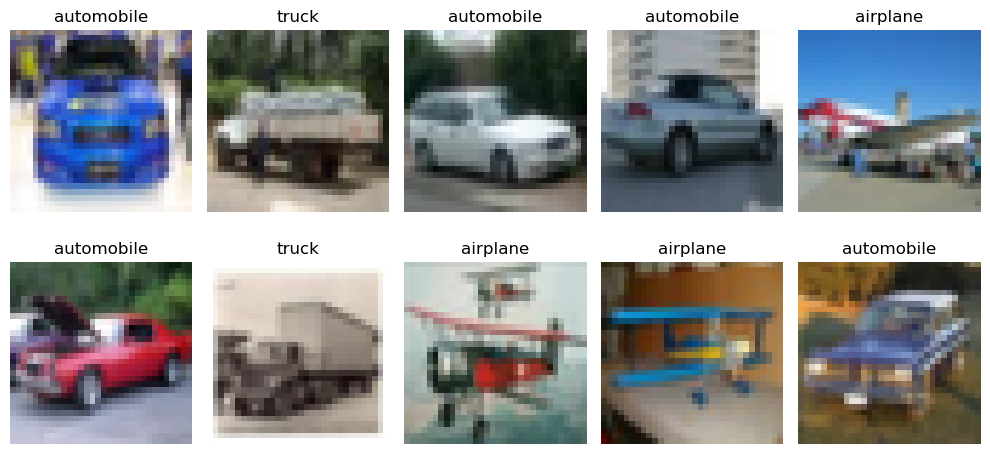

In [3]:
# Show a few images
plt.figure(figsize=(10, 5))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i])
    plt.title(CLASS_NAMES[y_train[i]])
    plt.axis("off")
plt.tight_layout()
plt.show()

# Create TensorFlow datasets
train_data = tf.data.Dataset.from_tensor_slices((x_train, y_train))
train_data = train_data.shuffle(10000).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

valid_data = tf.data.Dataset.from_tensor_slices((x_valid, y_valid))
valid_data = valid_data.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

test_data = tf.data.Dataset.from_tensor_slices((x_test, y_test))
test_data = test_data.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

In [4]:
# Build a simple VGG16 transfer-learning model
# The pretrained VGG16 layers are frozen, so training is faster.
base_model = VGG16(
    weights="imagenet",
    include_top=False,
    input_shape=(IMAGE_SIZE, IMAGE_SIZE, 3),
    pooling="avg"
)
base_model.trainable = False

inputs = layers.Input(shape=(32, 32, 3))
x = layers.Resizing(IMAGE_SIZE, IMAGE_SIZE)(inputs)
x = layers.RandomFlip("horizontal")(x)
x = layers.Lambda(preprocess_input)(x)
x = base_model(x)
outputs = layers.Dense(3, activation="softmax")(x)
model = Model(inputs, outputs)

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resizing (Resizing)             │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda (Lambda)                 │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg16 (Functional)              │ (None, 512)            │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 3)              │         1,539 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,716,227 (56.14 MB)

 Trainable params: 1,539 (6.01 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [5]:
# Train the model
history = model.fit(
    train_data,
    validation_data=valid_data,
    epochs=EPOCHS
)

Epoch 1/5


2026-10-24 14:48:53.069749: W external/local_xla/xla/tsl/framework/cpu_allocator_impl.cc:84] Allocation of 75497472 exceeds 10% of free system memory.
2026-10-24 14:48:53.119608: W external/local_xla/xla/tsl/framework/cpu_allocator_impl.cc:84] Allocation of 75497472 exceeds 10% of free system memory.


  1/375 ━━━━━━━━━━━━━━━━━━━━ 9:58 2s/step - accuracy: 0.3125 - loss: 9.0422

2026-10-24 14:48:53.776578: W external/local_xla/xla/tsl/framework/cpu_allocator_impl.cc:84] Allocation of 75497472 exceeds 10% of free system memory.
2026-10-24 14:48:53.792329: W external/local_xla/xla/tsl/framework/cpu_allocator_impl.cc:84] Allocation of 75497472 exceeds 10% of free system memory.


  2/375 ━━━━━━━━━━━━━━━━━━━━ 3:42 596ms/step - accuracy: 0.3203 - loss: 9.1777

2026-10-24 14:48:54.368377: W external/local_xla/xla/tsl/framework/cpu_allocator_impl.cc:84] Allocation of 75497472 exceeds 10% of free system memory.


375/375 ━━━━━━━━━━━━━━━━━━━━ 280s 745ms/step - accuracy: 0.8092 - loss: 0.9660 - val_accuracy: 0.8897 - val_loss: 0.4229
Epoch 2/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 283s 756ms/step - accuracy: 0.9118 - loss: 0.3148 - val_accuracy: 0.9130 - val_loss: 0.3158
Epoch 3/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 331s 781ms/step - accuracy: 0.9280 - loss: 0.2327 - val_accuracy: 0.9203 - val_loss: 0.2849
Epoch 4/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 274s 732ms/step - accuracy: 0.9351 - loss: 0.1986 - val_accuracy: 0.9240 - val_loss: 0.2565
Epoch 5/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 271s 724ms/step - accuracy: 0.9383 - loss: 0.1783 - val_accuracy: 0.9253 - val_loss: 0.2590


Test accuracy: 91.37%


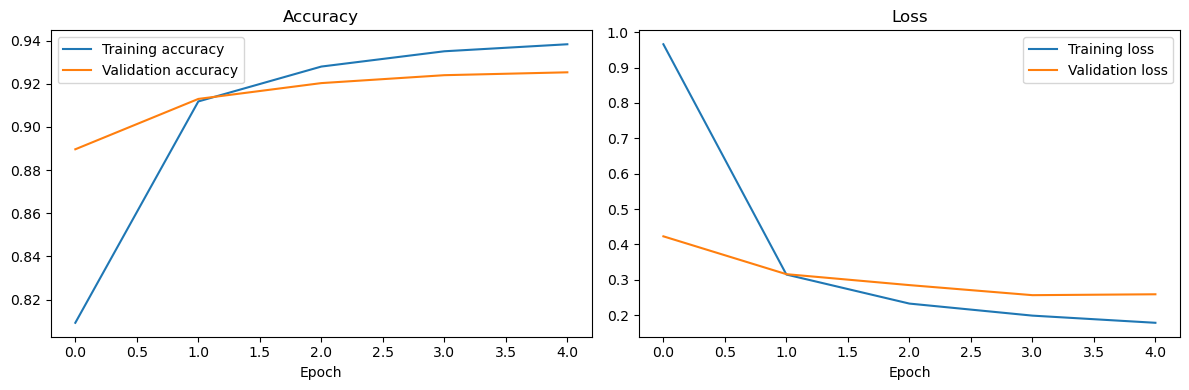

In [6]:
# Test the model
test_loss, test_accuracy = model.evaluate(test_data, verbose=0)
print(f"Test accuracy: {test_accuracy:.2%}")

# Plot accuracy and loss
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training accuracy")
plt.plot(history.history["val_accuracy"], label="Validation accuracy")
plt.title("Accuracy")
plt.xlabel("Epoch")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.title("Loss")
plt.xlabel("Epoch")
plt.legend()

plt.tight_layout()
plt.show()

In [7]:
# Check a few predictions
predictions = model.predict(x_test[:10], verbose=0)
predicted_labels = np.argmax(predictions, axis=1)

for i in range(10):
    actual = CLASS_NAMES[y_test[i]]
    predicted = CLASS_NAMES[predicted_labels[i]]
    print(f"Image {i + 1}: Actual = {actual}, Predicted = {predicted}")

Image 1: Actual = airplane, Predicted = airplane
Image 2: Actual = automobile, Predicted = truck
Image 3: Actual = automobile, Predicted = automobile
Image 4: Actual = airplane, Predicted = airplane
Image 5: Actual = truck, Predicted = truck
Image 6: Actual = truck, Predicted = truck
Image 7: Actual = airplane, Predicted = airplane
Image 8: Actual = truck, Predicted = truck
Image 9: Actual = airplane, Predicted = airplane
Image 10: Actual = truck, Predicted = truck
